In [47]:
DATA_RATE_PEAK = 2000   # KB/s, most likely value
DATA_RATE_STD = 500     # KB/s, spread before truncation
DATA_RATE_MIN = 1500    # KB/s
DATA_RATE_MAX = 2100    # KB/s

def generate_datarate():
    while True:
        rate = np.random.normal(DATA_RATE_PEAK, DATA_RATE_STD)
        if DATA_RATE_MIN <= rate <= DATA_RATE_MAX:
            return rate

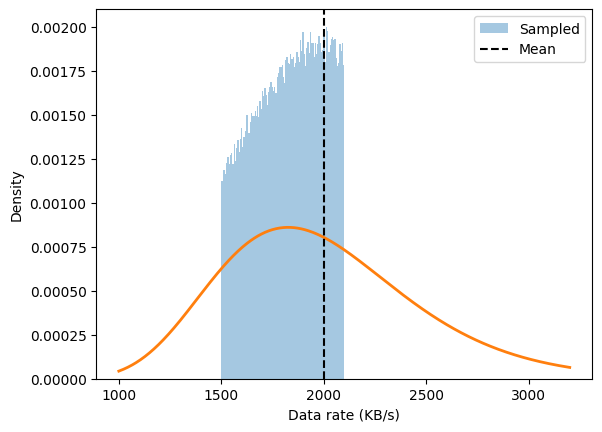

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import lognorm

sigma = np.sqrt(np.log(1 + (DATA_RATE_STD / DATA_RATE_PEAK) ** 2))
mu = np.log(DATA_RATE_PEAK) - 0.5 * sigma**2

x = np.linspace(1000, 3200, 500)
pdf = lognorm.pdf(x, s=sigma, scale=np.exp(mu))

samples = [generate_datarate() for _ in range(100_000)]

fig, ax = plt.subplots()
ax.hist(samples, bins=100, density=True, alpha=0.4, label="Sampled")
curve, = ax.plot(x, pdf, lw=2)
ax.axvline(DATA_RATE_PEAK, color="k", ls="--", label="Mean")

# Save the limits while the curve is still on the chart, then remove it
xlim, ylim = ax.get_xlim(), ax.get_ylim()
curve.remove()
ax.set_xlim(xlim)
ax.set_ylim(ylim)

ax.set_xlabel("Data rate (KB/s)")
ax.set_ylabel("Density")
ax.legend()
plt.show()